In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
# !pip install gensim
# Optional: pip install gensim before this
import gensim.downloader as api

# Load a small pre-trained GloVe model (50-dimensional)
glove = api.load("glove-wiki-gigaword-50")

# A small, hand-picked vocabulary to explore
words = [
    "king", "queen", "man", "woman",
    "doctor", "nurse", "engineer", "teacher",
    "paris", "france", "london", "england"
]

vectors = np.vstack([glove[w] for w in words])
vec_df = pd.DataFrame(vectors, index=words)
vec_df.head()

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
king,0.504510,0.68607,-0.59517,-0.022801,0.60046,-0.13498,-0.08813,0.47377,-0.617980,-0.31012,...,0.401020,1.16850,-1.01370,-0.215850,-0.15155,0.78321,-0.91241,-1.610600,-0.644260,-0.51042
queen,0.378540,1.82330,-1.26480,-0.104300,0.35829,0.60029,-0.17538,0.83767,-0.056798,-0.75795,...,0.459460,0.25302,-0.17837,-0.733980,-0.20025,0.23470,-0.56095,-2.283900,0.009275,-0.60284
man,-0.094386,0.43007,-0.17224,-0.455290,1.64470,0.40335,-0.37263,0.25071,-0.105880,0.10778,...,-0.086264,0.62549,-0.05760,0.293750,0.66005,-0.53115,-0.48233,-0.979250,0.531350,-0.11725
woman,-0.181530,0.64827,-0.58210,-0.494510,1.54150,1.34500,-0.43305,0.58059,0.355560,-0.25184,...,-0.251740,0.42123,0.48616,0.022325,0.55760,-0.85223,-0.23073,-1.313800,0.487640,-0.10467
doctor,0.669990,0.11698,-0.46322,-0.900120,0.56560,0.48980,-0.26031,0.71268,0.623380,0.02785,...,0.410300,0.71996,-0.16293,0.291060,0.47188,-0.15121,0.36688,-0.089993,0.377780,0.59818


In [7]:
pca = PCA(n_components=2)
coords_2d = pca.fit_transform(vectors)

viz_df = pd.DataFrame(coords_2d, columns=["pc1", "pc2"])
viz_df["word"] = words
viz_df

,pc1,pc2,word
0,-0.676858,-3.344143,king
1,-0.665033,-2.508571,queen
2,1.648065,-0.703754,man
3,2.186553,-0.212140,woman
4,2.134741,0.177947,doctor
5,2.643436,1.157770,nurse
6,1.279327,1.590129,engineer
7,2.315086,0.976006,teacher
8,-2.933945,2.095310,paris
9,-3.487677,1.649455,france


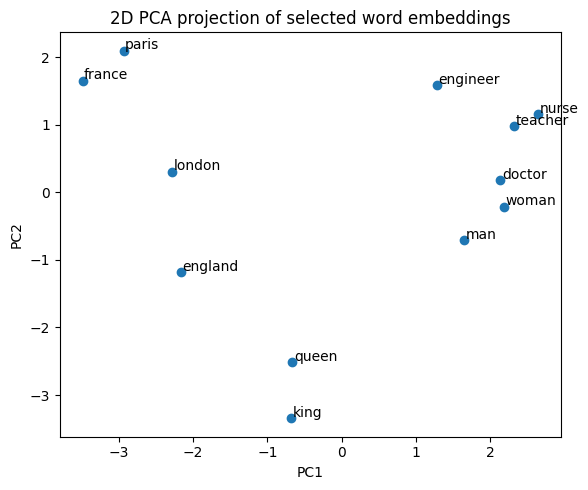

In [8]:
plt.figure(figsize=(6, 5))
plt.scatter(coords_2d[:, 0], coords_2d[:, 1])

for (x, y, word) in zip(coords_2d[:, 0], coords_2d[:, 1], words):
    plt.text(x + 0.02, y + 0.02, word)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("2D PCA projection of selected word embeddings")
plt.tight_layout()
plt.show()

In [9]:
def top_similar(query, top_n=5):
    return glove.most_similar(query, topn=top_n)

print("Nearest neighbours of 'doctor':")
for word, score in top_similar("doctor"):
    print(f"{word:12s}  cos_sim={score: .3f}")

Nearest neighbours of 'doctor':
nurse         cos_sim= 0.798
physician     cos_sim= 0.797
patient       cos_sim= 0.761
child         cos_sim= 0.756
teacher       cos_sim= 0.754


In [10]:
analogies = glove.most_similar(
    positive=["king", "woman"],
    negative=["man"],
    topn=5
)
print("king - man + woman ≈ ?")
for word, score in analogies:
    print(f"{word:12s}  cos_sim={score: .3f}")

king - man + woman ≈ ?
queen         cos_sim= 0.852
throne        cos_sim= 0.766
prince        cos_sim= 0.759
daughter      cos_sim= 0.747
elizabeth     cos_sim= 0.746


In [11]:
import torch
from torch import nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset

# Basic transform: resize to 224x224 and normalize like ImageNet
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

cifar_test = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=transform,
)

# Use a small subset for speed (e.g., first 500 images)
subset_indices = list(range(500))
cifar_subset = Subset(cifar_test, subset_indices)
loader = DataLoader(cifar_subset, batch_size=64, shuffle=False)

# Load a pre-trained ResNet-18
resnet = models.resnet18(pretrained=True)  # if this warns, see weights="IMAGENET1K_V1"
resnet.eval()

# Remove the final classification layer to get embeddings from the penultimate layer
embedding_model = nn.Sequential(*list(resnet.children())[:-1])
embedding_model.eval()

100%|██████████| 170M/170M [26:34<00:00, 107kB/s]
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 89.8MB/s]


Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Con

In [12]:
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
embedding_model = embedding_model.to(device)

all_embeddings = []
all_labels = []

with torch.no_grad():
    for imgs, labels in loader:
        imgs = imgs.to(device)
        feats = embedding_model(imgs)         # shape: (B, 512, 1, 1)
        feats = feats.view(feats.size(0), -1) # shape: (B, 512)
        all_embeddings.append(feats.cpu().numpy())
        all_labels.append(labels.numpy())

embeddings = np.vstack(all_embeddings)  # (N, 512)
labels = np.concatenate(all_labels)     # (N,)

In [13]:
from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
coords_2d = pca.fit_transform(embeddings)

class_names = cifar_test.classes  # list of 10 class names

viz_df = pd.DataFrame({
    "pc1": coords_2d[:, 0],
    "pc2": coords_2d[:, 1],
    "label": labels,
    "class_name": [class_names[i] for i in labels],
})
viz_df.head()

,pc1,pc2,label,class_name
0,-0.651809,4.839281,3,cat
1,-6.464311,-2.202712,8,ship
2,-7.807767,-0.514024,8,ship
3,-0.458074,-1.641300,0,airplane
4,8.980953,-5.555719,6,frog


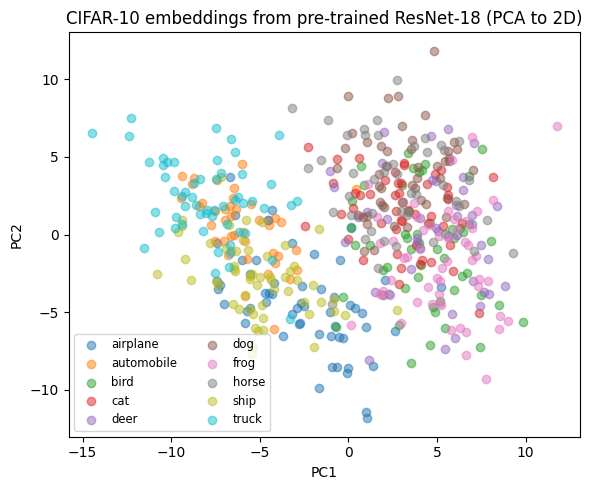

In [14]:
plt.figure(figsize=(6, 5))
for class_idx, class_name in enumerate(class_names):
    mask = (labels == class_idx)
    plt.scatter(
        coords_2d[mask, 0],
        coords_2d[mask, 1],
        alpha=0.5,
        label=class_name,
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("CIFAR-10 embeddings from pre-trained ResNet-18 (PCA to 2D)")
plt.legend(fontsize="small", ncol=2)
plt.tight_layout()
plt.show()

In [15]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_val, y_train, y_val = train_test_split(
    embeddings, labels, test_size=0.3, random_state=42, stratify=labels
)

knn = KNeighborsClassifier(n_neighbors=5, metric="cosine")
knn.fit(X_train, y_train)
y_pred = knn.predict(X_val)

acc = accuracy_score(y_val, y_pred)
print(f"Validation accuracy with k-NN on ResNet embeddings: {acc:.3f}")

Validation accuracy with k-NN on ResNet embeddings: 0.607
